In [1]:
#cell 1
import torch
import numpy as np
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not detected. Check Kaggle Accelerator settings.")

print("NumPy:", np.__version__)

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
NumPy: 2.1.3


In [2]:
#cell 2
import os
import subprocess

REPO_URL = "https://github.com/arcprize/ARC-AGI-2.git"

PROJECT_DIR = "/kaggle/working/GridMind"
DATA_DIR = os.path.join(PROJECT_DIR, "data")

os.makedirs(PROJECT_DIR, exist_ok=True)

if not os.path.exists(os.path.join(PROJECT_DIR, ".git")):

    subprocess.run(
        [
            "git", "clone",
            "--depth", "1",
            REPO_URL,
            PROJECT_DIR
        ],
        check=True
    )

print("Dataset repository downloaded!")
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

Cloning into '/kaggle/working/GridMind'...


Dataset repository downloaded!
Project directory: /kaggle/working/GridMind
Data directory: /kaggle/working/GridMind/data


In [3]:
#cell 3
import os

TRAIN_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "training"
)

EVAL_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "evaluation"
)

print("Training directory exists:", os.path.exists(TRAIN_DIR))
print("Evaluation directory exists:", os.path.exists(EVAL_DIR))

train_files = [
    f for f in os.listdir(TRAIN_DIR)
    if f.endswith(".json")
]

eval_files = [
    f for f in os.listdir(EVAL_DIR)
    if f.endswith(".json")
]

print("Training tasks:", len(train_files))
print("Evaluation tasks:", len(eval_files))

Training directory exists: True
Evaluation directory exists: True
Training tasks: 1000
Evaluation tasks: 120


In [4]:
#cell 4
folders = [
    "src",
    "checkpoints",
    "experiments",
    "outputs",
    "outputs/visualizations",
    "outputs/predictions"
]

for folder in folders:

    path = os.path.join(PROJECT_DIR, folder)

    os.makedirs(path, exist_ok=True)

print("GridMind project folders created!")

for folder in folders:
    print("✓", folder)

GridMind project folders created!
✓ src
✓ checkpoints
✓ experiments
✓ outputs
✓ outputs/visualizations
✓ outputs/predictions


In [5]:
#cell 5
import json

first_task_file = sorted(train_files)[0]

first_task_path = os.path.join(
    TRAIN_DIR,
    first_task_file
)

with open(first_task_path, "r") as f:
    task = json.load(f)

print("Task ID:", first_task_file.replace(".json", ""))

print("Number of training examples:", len(task["train"]))
print("Number of test examples:", len(task["test"]))

print("\nFirst training input:")
print(np.array(task["train"][0]["input"]))

print("\nFirst training output:")
print(np.array(task["train"][0]["output"]))

print("\nTest input:")
print(np.array(task["test"][0]["input"]))

Task ID: 00576224
Number of training examples: 2
Number of test examples: 1

First training input:
[[7 9]
 [4 3]]

First training output:
[[7 9 7 9 7 9]
 [4 3 4 3 4 3]
 [9 7 9 7 9 7]
 [3 4 3 4 3 4]
 [7 9 7 9 7 9]
 [4 3 4 3 4 3]]

Test input:
[[3 2]
 [7 8]]


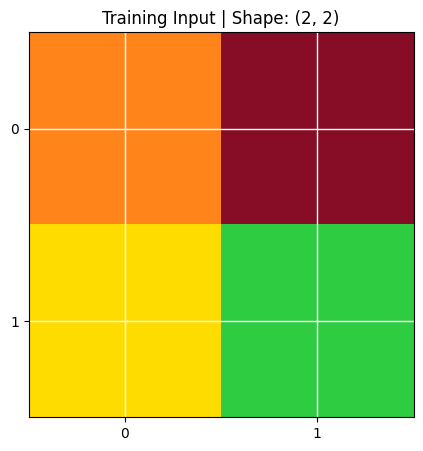

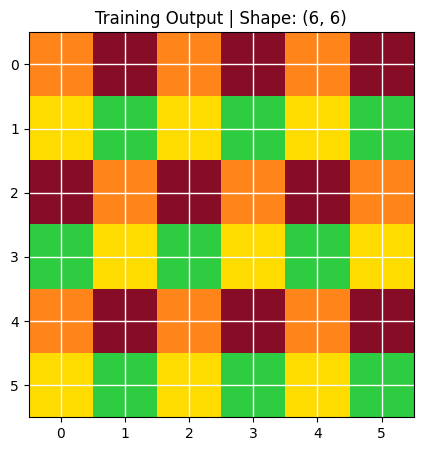

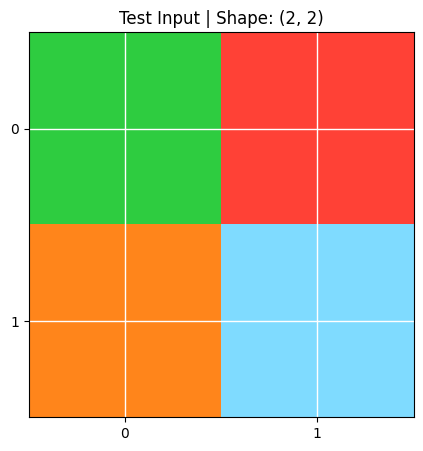

In [6]:
#cell 7
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ARC_COLORS = [
    "#000000",  # 0 - Black
    "#0074D9",  # 1 - Blue
    "#FF4136",  # 2 - Red
    "#2ECC40",  # 3 - Green
    "#FFDC00",  # 4 - Yellow
    "#AAAAAA",  # 5 - Grey
    "#F012BE",  # 6 - Magenta
    "#FF851B",  # 7 - Orange
    "#7FDBFF",  # 8 - Cyan
    "#870C25"   # 9 - Maroon
]

cmap = ListedColormap(ARC_COLORS)


def show_grid(grid, title="ARC Grid"):

    grid = np.array(grid)

    plt.figure(figsize=(5, 5))

    plt.imshow(
        grid,
        cmap=cmap,
        vmin=0,
        vmax=9
    )

    plt.title(
        f"{title} | Shape: {grid.shape}"
    )

    plt.xticks(range(grid.shape[1]))
    plt.yticks(range(grid.shape[0]))

    plt.grid(
        color="white",
        linewidth=1
    )

    plt.show()


show_grid(
    task["train"][0]["input"],
    "Training Input"
)

show_grid(
    task["train"][0]["output"],
    "Training Output"
)

show_grid(
    task["test"][0]["input"],
    "Test Input"
)

In [7]:
#cell 8
from collections import Counter

stats = {
    "total_tasks": 0,
    "total_train_pairs": 0,
    "total_test_pairs": 0,
    "grid_shapes": [],
    "colors": Counter(),
    "train_examples_per_task": []
}

for filename in train_files:

    path = os.path.join(TRAIN_DIR, filename)

    with open(path, "r") as f:
        data = json.load(f)

    stats["total_tasks"] += 1

    stats["total_train_pairs"] += len(data["train"])
    stats["total_test_pairs"] += len(data["test"])

    stats["train_examples_per_task"].append(
        len(data["train"])
    )

    for pair in data["train"]:

        for key in ["input", "output"]:

            grid = np.array(pair[key])

            stats["grid_shapes"].append(grid.shape)

            unique, counts = np.unique(
                grid,
                return_counts=True
            )

            for color, count in zip(unique, counts):

                stats["colors"][int(color)] += int(count)


print("Total Tasks:", stats["total_tasks"])

print("Training Pairs:", stats["total_train_pairs"])

print("Test Pairs:", stats["total_test_pairs"])

print(
    "Average training examples:",
    np.mean(stats["train_examples_per_task"])
)

print(
    "Minimum grid dimension:",
    min(min(s) for s in stats["grid_shapes"])
)

print(
    "Maximum grid dimension:",
    max(max(s) for s in stats["grid_shapes"])
)

print("\nColor frequency:")

for color, count in sorted(stats["colors"].items()):

    print(f"Color {color}: {count}")

Total Tasks: 1000
Training Pairs: 3232
Test Pairs: 1076
Average training examples: 3.232
Minimum grid dimension: 1
Maximum grid dimension: 30

Color frequency:
Color 0: 509919
Color 1: 78058
Color 2: 64134
Color 3: 58612
Color 4: 48896
Color 5: 37383
Color 6: 23560
Color 7: 62668
Color 8: 99251
Color 9: 12113


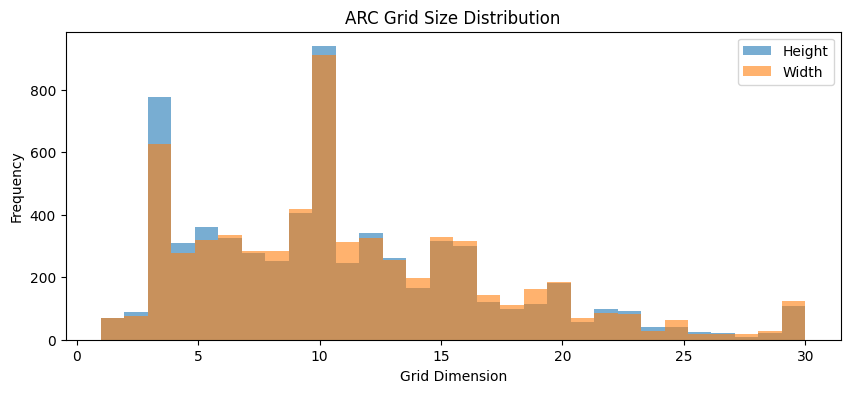

In [8]:
#cell 9
heights = [s[0] for s in stats["grid_shapes"]]
widths = [s[1] for s in stats["grid_shapes"]]

plt.figure(figsize=(10, 4))

plt.hist(
    heights,
    bins=30,
    alpha=0.6,
    label="Height"
)

plt.hist(
    widths,
    bins=30,
    alpha=0.6,
    label="Width"
)

plt.xlabel("Grid Dimension")
plt.ylabel("Frequency")
plt.title("ARC Grid Size Distribution")

plt.legend()
plt.show()

In [9]:
#cell 10
from sklearn.model_selection import train_test_split

task_ids = sorted([
    f.replace(".json", "")
    for f in train_files
])

train_ids, val_ids = train_test_split(
    task_ids,
    test_size=0.20,
    random_state=42
)

print("Training tasks:", len(train_ids))
print("Validation tasks:", len(val_ids))

# Save split
split_path = os.path.join(
    PROJECT_DIR,
    "experiments",
    "task_split.json"
)

with open(split_path, "w") as f:

    json.dump(
        {
            "train_ids": sorted(train_ids),
            "val_ids": sorted(val_ids),
            "random_seed": 42
        },
        f,
        indent=2
    )

print("Task split saved:", split_path)

Training tasks: 800
Validation tasks: 200
Task split saved: /kaggle/working/GridMind/experiments/task_split.json


In [10]:
#cell 11
import os
import json
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

GRID_SIZE = 30
NUM_CHANNELS = 11
NUM_COLORS = 10

def encode_grid(grid):
    grid = np.array(grid, dtype=np.int64)

    h, w = grid.shape

    encoded = np.zeros(
        (NUM_CHANNELS, GRID_SIZE, GRID_SIZE),
        dtype=np.float32
    )

    # One-hot colour encoding
    for color in range(NUM_COLORS):
        encoded[color, :h, :w] = (grid == color)

    # Valid-cell mask
    encoded[10, :h, :w] = 1.0

    return torch.tensor(encoded), h, w


def encode_target(grid):
    grid = np.array(grid, dtype=np.int64)

    h, w = grid.shape

    target = torch.full(
        (GRID_SIZE, GRID_SIZE),
        -100,
        dtype=torch.long
    )

    target[:h, :w] = torch.tensor(grid)

    return target, h, w

In [11]:
#cell 12
class GridMindDataset(Dataset):

    def __init__(self, task_ids, data_dir, seed=42):
        self.task_ids = list(task_ids)
        self.data_dir = data_dir
        self.seed = seed
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __len__(self):
        return len(self.task_ids)

    def __getitem__(self, idx):

        task_id = self.task_ids[idx]
        file_path = os.path.join(
            self.data_dir,
            task_id + ".json"
        )

        with open(file_path, "r") as f:
            task = json.load(f)

        examples = task["train"]

        # Deterministic but different query across epochs
        rng = random.Random(
            self.seed + self.epoch * 100003 + idx
        )

        query_idx = rng.randrange(len(examples))

        query_example = examples[query_idx]

        support_examples = [
            example
            for i, example in enumerate(examples)
            if i != query_idx
        ]

        support_inputs = []
        support_outputs = []

        for example in support_examples:

            x, _, _ = encode_grid(example["input"])
            y, _, _ = encode_grid(example["output"])

            support_inputs.append(x)
            support_outputs.append(y)

        query_input, qh, qw = encode_grid(
            query_example["input"]
        )

        query_target, th, tw = encode_target(
            query_example["output"]
        )

        return {
            "support_inputs": torch.stack(support_inputs),
            "support_outputs": torch.stack(support_outputs),
            "query_input": query_input,
            "query_target": query_target,
            "query_size": torch.tensor([qh, qw]),
            "target_size": torch.tensor([th, tw]),
            "task_id": task_id
        }

In [12]:
#cell 13
def gridmind_collate(batch):

    batch_size = len(batch)
    max_support = max(
        item["support_inputs"].shape[0]
        for item in batch
    )

    support_inputs = torch.zeros(
        batch_size, max_support,
        NUM_CHANNELS, GRID_SIZE, GRID_SIZE
    )

    support_outputs = torch.zeros_like(support_inputs)

    support_mask = torch.zeros(
        batch_size, max_support,
        dtype=torch.bool
    )

    for i, item in enumerate(batch):

        n = item["support_inputs"].shape[0]

        support_inputs[i, :n] = item["support_inputs"]
        support_outputs[i, :n] = item["support_outputs"]

        support_mask[i, :n] = True

    return {
        "support_inputs": support_inputs,
        "support_outputs": support_outputs,
        "support_mask": support_mask,

        "query_input": torch.stack([
            item["query_input"] for item in batch
        ]),

        "query_target": torch.stack([
            item["query_target"] for item in batch
        ]),

        "query_size": torch.stack([
            item["query_size"] for item in batch
        ]),

        "target_size": torch.stack([
            item["target_size"] for item in batch
        ]),

        "task_id": [
            item["task_id"] for item in batch
        ]
    }

In [13]:
#cell 14
train_dataset = GridMindDataset(
    train_ids,
    TRAIN_DIR,
    seed=42
)

val_dataset = GridMindDataset(
    val_ids,
    TRAIN_DIR,
    seed=1000
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=gridmind_collate,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=gridmind_collate,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 100
Validation batches: 25


In [14]:
#cell 15
batch = next(iter(train_loader))

for key, value in batch.items():

    if torch.is_tensor(value):
        print(key, value.shape, value.dtype)

    elif isinstance(value, list):
        print(key, value[:3])

support_inputs torch.Size([8, 2, 11, 30, 30]) torch.float32
support_outputs torch.Size([8, 2, 11, 30, 30]) torch.float32
support_mask torch.Size([8, 2]) torch.bool
query_input torch.Size([8, 11, 30, 30]) torch.float32
query_target torch.Size([8, 30, 30]) torch.int64
query_size torch.Size([8, 2]) torch.int64
target_size torch.Size([8, 2]) torch.int64
task_id ['e26a3af2', '7e576d6e', 'bf32578f']


In [47]:
#cell 16
class GridMindConfig:
    grid_size = 30
    input_channels = 11
    num_colors = 10

    hidden_dim = 128
    num_heads = 4
    num_transformer_layers = 3
    dropout = 0.1

    max_support_pairs = 10

In [48]:
#cell 17
class GridEncoderV3(nn.Module):

    def __init__(self, config):
        super().__init__()

        self.high_encoder = nn.Sequential(
            nn.Conv2d(
                config.input_channels,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.GELU(),

            nn.Conv2d(
                64,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.GELU()
        )

        self.downsample = nn.Sequential(
            nn.Conv2d(
                64,
                96,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(96),
            nn.GELU(),

            nn.Conv2d(
                96,
                config.hidden_dim,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(config.hidden_dim),
            nn.GELU()
        )
    
    def forward(self, x):

        high_features = self.high_encoder(x)

        low_features = self.downsample(
            high_features
        )

        return high_features, low_features
        
class PositionalEmbedding2D(nn.Module):

    def __init__(self, dim, grid_size=15):
        super().__init__()

        self.row_embedding = nn.Parameter(
            torch.randn(1, grid_size, 1, dim) * 0.02
        )

        self.col_embedding = nn.Parameter(
            torch.randn(1, 1, grid_size, dim) * 0.02
        )

    def forward(self, x):

        return (
            x
            + self.row_embedding
            + self.col_embedding
        )

In [49]:
#cell 18
class GridMindV3(nn.Module):

    def __init__(self, config):
        super().__init__()

        self.config = config

        d = config.hidden_dim
        g = config.grid_size
        max_pairs = config.max_support_pairs

        # Shared visual encoder
        self.encoder = GridEncoderV3(config)

        # 2D position information
        self.position_embedding = PositionalEmbedding2D(
            d,
            grid_size=15
        )

        # Input/output role embeddings
        self.role_embedding = nn.Parameter(
            torch.randn(1, 2, 1, d) * 0.02
        )

        # Identity of each support pair
        self.pair_embedding = nn.Parameter(
            torch.randn(1, max_pairs, 1, d) * 0.02
        )

        # Transformer reasoning
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d,
            nhead=config.num_heads,
            dim_feedforward=4 * d,
            dropout=config.dropout,
            batch_first=True,
            norm_first=True
        )

        self.reasoner = nn.TransformerDecoder(
            decoder_layer,
            num_layers=config.num_transformer_layers
        )

        self.norm = nn.LayerNorm(d)

        # High-resolution skip decoder
        self.grid_decoder = nn.Sequential(

            nn.Conv2d(
                d + 64 + config.input_channels,
                128,
                kernel_size=3,
                padding=1
            ),
            nn.GELU(),

            nn.Conv2d(
                128,
                96,
                kernel_size=3,
                padding=1
            ),
            nn.GELU(),

            nn.Conv2d(
                96,
                config.num_colors,
                kernel_size=1
            )
        )

        # Output dimension prediction
        self.size_head = nn.Sequential(

            nn.Linear(2 * d, d),
            nn.GELU(),

            nn.Dropout(config.dropout),

            nn.Linear(d, 2 * g)
        )

    def encode(self, x):

        high, low = self.encoder(x)

        B, D, H, W = low.shape

        tokens = low.flatten(2).transpose(1, 2)

        tokens = tokens.reshape(
            B, 15, 15, D
        )

        tokens = self.position_embedding(tokens)

        tokens = tokens.reshape(
            B, 225, D
        )

        return high, tokens

    def make_spatial_mask(self, x):

        mask = x[:, 10:11]

        mask = F.max_pool2d(
            mask,
            kernel_size=2,
            stride=2
        )

        return mask.flatten(1) > 0

    def forward(
        self,
        support_inputs,
        support_outputs,
        query_input,
        support_mask
    ):

        B, S, C, H, W = support_inputs.shape

        if S > self.config.max_support_pairs:
            raise ValueError("Too many support pairs")

        # Encode support examples
        sx = support_inputs.reshape(
            B * S, C, H, W
        )

        sy = support_outputs.reshape(
            B * S, C, H, W
        )

        _, sx_tokens = self.encode(sx)
        _, sy_tokens = self.encode(sy)

        # Restore support dimensions
        sx_tokens = sx_tokens.reshape(
            B, S, 225, -1
        )

        sy_tokens = sy_tokens.reshape(
            B, S, 225, -1
        )

        # Add role embeddings
        sx_tokens = (
            sx_tokens + self.role_embedding[:, 0]
        )

        sy_tokens = (
            sy_tokens + self.role_embedding[:, 1]
        )

        # Add pair identity embeddings
        pair_emb = self.pair_embedding[:, :S]

        sx_tokens = sx_tokens + pair_emb
        sy_tokens = sy_tokens + pair_emb

        # Combine input/output support memory
        support_memory = torch.cat(
            [sx_tokens, sy_tokens],
            dim=2
        )

        support_memory = support_memory.reshape(
            B, S * 450, -1
        )

        # Encode query
        query_high, query_tokens = self.encode(
            query_input
        )

        # Support spatial masks
        input_mask = self.make_spatial_mask(
            sx
        ).reshape(B, S, 225)

        output_mask = self.make_spatial_mask(
            sy
        ).reshape(B, S, 225)

        memory_mask = torch.cat(
            [input_mask, output_mask],
            dim=2
        )

        memory_mask = (
            memory_mask &
            support_mask.unsqueeze(-1)
        )

        memory_mask = memory_mask.reshape(
            B, S * 450
        )

        query_mask = self.make_spatial_mask(
            query_input
        )

        # Cross-attention
        reasoning = self.reasoner(
            tgt=query_tokens,
            memory=support_memory,
            tgt_key_padding_mask=~query_mask,
            memory_key_padding_mask=~memory_mask
        )

        reasoning = self.norm(reasoning)

        # Convert reasoning tokens to feature map
        spatial = reasoning.transpose(
            1, 2
        ).reshape(B, self.config.hidden_dim, 15, 15)

        # Upsample reasoning features
        spatial = F.interpolate(
            spatial,
            size=(30, 30),
            mode="nearest"
        )

        # Combine with high-resolution CNN features
        decoder_input = torch.cat(
            [
                spatial,
                query_high,
                query_input
            ],
            dim=1
        )

        colour_logits = self.grid_decoder(
            decoder_input
        )

        # Masked pooling
        valid_query = query_mask.unsqueeze(-1).float()

        query_pooled = (
            query_tokens * valid_query
        ).sum(dim=1) / valid_query.sum(dim=1).clamp(min=1)

        reasoning_pooled = (
            reasoning * valid_query
        ).sum(dim=1) / valid_query.sum(dim=1).clamp(min=1)

        pooled = torch.cat(
            [query_pooled, reasoning_pooled],
            dim=-1
        )

        size_logits = self.size_head(pooled)

        return {
            "colour_logits": colour_logits,
            "height_logits": size_logits[:, :30],
            "width_logits": size_logits[:, 30:]
        }

In [50]:
#cell 19
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

config = GridMindConfig()

model = GridMindV3(config).to(device)

print("GridMind V3 initialized!")
print("Device:", device)

print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)

GridMind V3 initialized!
Device: cuda
Total parameters: 1395782


In [51]:
#cell 20
batch = next(iter(train_loader))

test_batch = {
    key: value[:2] if torch.is_tensor(value) else value[:2]
    for key, value in batch.items()
}

support_inputs = test_batch["support_inputs"].to(device)
support_outputs = test_batch["support_outputs"].to(device)
query_input = test_batch["query_input"].to(device)
support_mask = test_batch["support_mask"].to(device)

model.eval()

with torch.no_grad():

    predictions = model(
        support_inputs,
        support_outputs,
        query_input,
        support_mask
    )

for key, value in predictions.items():
    print(key, value.shape)

colour_logits torch.Size([2, 10, 30, 30])
height_logits torch.Size([2, 30])
width_logits torch.Size([2, 30])


In [52]:
#cell 21
import torch
import torch.nn as nn
import torch.nn.functional as F

def calculate_loss(predictions, batch):

    target = batch["query_target"].to(device)
    target_size = batch["target_size"].to(device)

    colour_logits = predictions["colour_logits"]
    height_logits = predictions["height_logits"]
    width_logits = predictions["width_logits"]

    colour_loss = F.cross_entropy(
        colour_logits,
        target,
        ignore_index=-100
    )

    height_loss = F.cross_entropy(
        height_logits,
        target_size[:, 0] - 1
    )

    width_loss = F.cross_entropy(
        width_logits,
        target_size[:, 1] - 1
    )

    total_loss = (
        colour_loss
        + height_loss
        + width_loss
    )

    return {
        "total": total_loss,
        "colour": colour_loss,
        "height": height_loss,
        "width": width_loss
    }

In [53]:
#cell 22
import os

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR, "checkpoints"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "gridmind_v3_best.pt"
)

print("V3 checkpoint:", BEST_MODEL_PATH)

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR, "checkpoints"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR, "gridmind_best.pt"
)

V3 checkpoint: /kaggle/working/GridMind/checkpoints/gridmind_v3_best.pt


In [54]:
#cell 23
@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    total_loss = 0.0
    total_batches = 0

    correct_cells = 0
    total_cells = 0

    correct_sizes = 0
    exact_matches = 0
    total_tasks = 0

    for batch in loader:

        support_inputs = batch["support_inputs"].to(device)
        support_outputs = batch["support_outputs"].to(device)
        query_input = batch["query_input"].to(device)
        support_mask = batch["support_mask"].to(device)

        target = batch["query_target"].to(device)
        target_size = batch["target_size"].to(device)

        predictions = model(
            support_inputs,
            support_outputs,
            query_input,
            support_mask
        )

        losses = calculate_loss(predictions, batch)

        total_loss += losses["total"].item()
        total_batches += 1

        predicted_grid = predictions[
            "colour_logits"
        ].argmax(dim=1)

        predicted_height = (
            predictions["height_logits"].argmax(dim=1) + 1
        )

        predicted_width = (
            predictions["width_logits"].argmax(dim=1) + 1
        )

        for i in range(target.shape[0]):

            true_h, true_w = target_size[i].tolist()

            valid_target = target[i, :true_h, :true_w]
            valid_prediction = predicted_grid[i, :true_h, :true_w]

            correct_cells += (
                valid_prediction == valid_target
            ).sum().item()

            total_cells += true_h * true_w

            size_correct = (
                predicted_height[i].item() == true_h
                and predicted_width[i].item() == true_w
            )

            if size_correct:
                correct_sizes += 1

            grid_correct = torch.equal(
                valid_prediction,
                valid_target
            )

            if size_correct and grid_correct:
                exact_matches += 1

            total_tasks += 1

    return {
        "loss": total_loss / max(total_batches, 1),
        "cell_accuracy": correct_cells / max(total_cells, 1),
        "size_accuracy": correct_sizes / max(total_tasks, 1),
        "exact_match": exact_matches / max(total_tasks, 1)
    }

In [55]:
#cell 24
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

EPOCHS = 30
PATIENCE = 7

best_val_loss = float("inf")
epochs_without_improvement = 0

history = []

for epoch in range(EPOCHS):

    train_dataset.set_epoch(epoch)

    model.train()

    running_loss = 0.0
    batches = 0

    for batch in train_loader:

        support_inputs = batch["support_inputs"].to(device)
        support_outputs = batch["support_outputs"].to(device)
        query_input = batch["query_input"].to(device)
        support_mask = batch["support_mask"].to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions = model(
            support_inputs,
            support_outputs,
            query_input,
            support_mask
        )

        losses = calculate_loss(predictions, batch)

        losses["total"].backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += losses["total"].item()
        batches += 1

    train_loss = running_loss / max(batches, 1)

    # Validation query remains fixed
    val_metrics = evaluate(model, val_loader)

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **val_metrics,
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Cell Acc: {val_metrics['cell_accuracy']:.4f} | "
        f"Size Acc: {val_metrics['size_accuracy']:.4f} | "
        f"Exact Match: {val_metrics['exact_match']:.4f}"
    )

    if val_metrics["loss"] < best_val_loss:

        best_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "config": {
                "hidden_dim": config.hidden_dim,
                "num_heads": config.num_heads,
                "num_transformer_layers": config.num_transformer_layers
            }
        }, BEST_MODEL_PATH)

        print("  Best checkpoint saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\nTraining completed.")
print("Best validation loss:", best_val_loss)
print("Checkpoint:", BEST_MODEL_PATH)

Epoch 01/30 | Train Loss: 7.5783 | Val Loss: 7.2276 | Cell Acc: 0.7046 | Size Acc: 0.1350 | Exact Match: 0.0050
  Best checkpoint saved!
Epoch 02/30 | Train Loss: 6.5091 | Val Loss: 6.4871 | Cell Acc: 0.7370 | Size Acc: 0.1550 | Exact Match: 0.0000
  Best checkpoint saved!
Epoch 03/30 | Train Loss: 5.8429 | Val Loss: 6.0804 | Cell Acc: 0.7257 | Size Acc: 0.2050 | Exact Match: 0.0000
  Best checkpoint saved!
Epoch 04/30 | Train Loss: 5.4229 | Val Loss: 5.8892 | Cell Acc: 0.7526 | Size Acc: 0.2100 | Exact Match: 0.0000
  Best checkpoint saved!
Epoch 05/30 | Train Loss: 5.1502 | Val Loss: 5.4777 | Cell Acc: 0.7217 | Size Acc: 0.2150 | Exact Match: 0.0000
  Best checkpoint saved!
Epoch 06/30 | Train Loss: 4.8711 | Val Loss: 5.7794 | Cell Acc: 0.7620 | Size Acc: 0.1900 | Exact Match: 0.0000
Epoch 07/30 | Train Loss: 4.7702 | Val Loss: 5.2438 | Cell Acc: 0.7595 | Size Acc: 0.2750 | Exact Match: 0.0000
  Best checkpoint saved!
Epoch 08/30 | Train Loss: 4.5280 | Val Loss: 5.6023 | Cell Acc: 0.

In [56]:
#cell 25
train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=gridmind_collate,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=gridmind_collate,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 400
Validation batches: 100


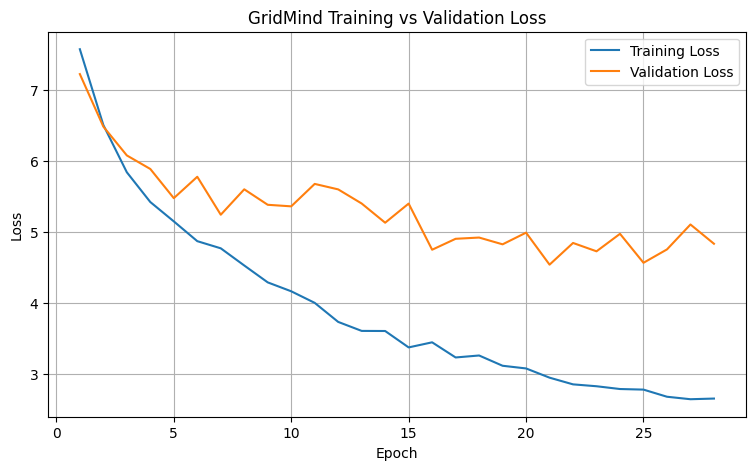

In [57]:
#cell 26
import matplotlib.pyplot as plt

epochs = [x["epoch"] for x in history]
train_losses = [x["train_loss"] for x in history]
val_losses = [x["loss"] for x in history]

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GridMind Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [58]:
# Load best validation checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Best Epoch:", checkpoint["epoch"])
print("Best Validation Loss:", checkpoint["best_val_loss"])

# Evaluate best checkpoint
val_metrics = evaluate(model, val_loader)

print("\n--- GridMind Validation Results ---")
print(f"Cell Accuracy: {val_metrics['cell_accuracy']:.4%}")
print(f"Size Accuracy: {val_metrics['size_accuracy']:.4%}")
print(f"Exact Match: {val_metrics['exact_match']:.4%}")

Best Epoch: 21
Best Validation Loss: 4.539649589061737

--- GridMind Validation Results ---
Cell Accuracy: 78.7307%
Size Accuracy: 44.5000%
Exact Match: 0.5000%


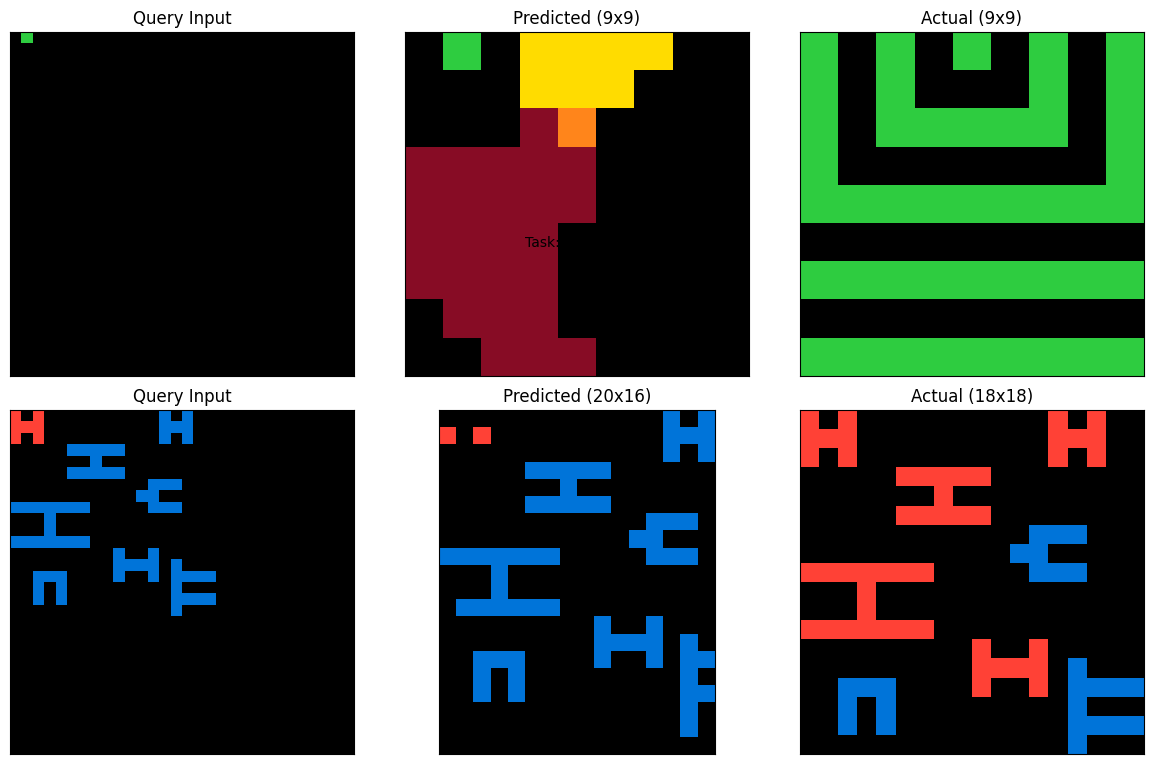

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import torch

ARC_COLORS = [
    "#000000", "#0074D9", "#FF4136", "#2ECC40",
    "#FFDC00", "#AAAAAA", "#F012BE", "#FF851B",
    "#7FDBFF", "#870C25"
]

from matplotlib.colors import ListedColormap

cmap = ListedColormap(ARC_COLORS)


def decode_input(encoded):
    return encoded[:10].argmax(dim=0).cpu().numpy()


def show_predictions(model, loader, count=8):

    model.eval()
    batch = next(iter(loader))

    with torch.no_grad():

        predictions = model(
            batch["support_inputs"][:count].to(device),
            batch["support_outputs"][:count].to(device),
            batch["query_input"][:count].to(device),
            batch["support_mask"][:count].to(device)
        )

    predicted_grids = predictions["colour_logits"].argmax(dim=1)

    predicted_heights = predictions["height_logits"].argmax(dim=1) + 1
    predicted_widths = predictions["width_logits"].argmax(dim=1) + 1

    n = min(count, len(batch["task_id"]))

    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):

        query = decode_input(batch["query_input"][i])

        true_h, true_w = batch["target_size"][i].tolist()

        target = batch["query_target"][i, :true_h, :true_w].numpy()

        ph = predicted_heights[i].item()
        pw = predicted_widths[i].item()

        predicted = predicted_grids[i, :ph, :pw].cpu().numpy()

        axes[i, 0].imshow(query, cmap=cmap, vmin=0, vmax=9)
        axes[i, 0].set_title("Query Input")

        axes[i, 1].imshow(predicted, cmap=cmap, vmin=0, vmax=9)
        axes[i, 1].set_title(f"Predicted ({ph}x{pw})")

        axes[i, 2].imshow(target, cmap=cmap, vmin=0, vmax=9)
        axes[i, 2].set_title(f"Actual ({true_h}x{true_w})")

        for ax in axes[i]:
            ax.set_xticks([])
            ax.set_yticks([])

        fig.suptitle(
            f"Task: {batch['task_id'][i]}",
            fontsize=10,
            y=1 - (i / (n + 1))
        )

    plt.tight_layout()
    plt.show()


show_predictions(model, val_loader, count=8)

In [37]:
@torch.no_grad()
def dimension_diagnostics(model, loader):

    model.eval()

    total = 0
    height_correct = 0
    width_correct = 0
    both_correct = 0

    for batch in loader:

        predictions = model(
            batch["support_inputs"].to(device),
            batch["support_outputs"].to(device),
            batch["query_input"].to(device),
            batch["support_mask"].to(device)
        )

        true_size = batch["target_size"].to(device)

        pred_h = predictions["height_logits"].argmax(1) + 1
        pred_w = predictions["width_logits"].argmax(1) + 1

        height_correct += (pred_h == true_size[:, 0]).sum().item()
        width_correct += (pred_w == true_size[:, 1]).sum().item()

        both_correct += (
            (pred_h == true_size[:, 0]) &
            (pred_w == true_size[:, 1])
        ).sum().item()

        total += true_size.shape[0]

    print("Height Accuracy:", height_correct / total)
    print("Width Accuracy:", width_correct / total)
    print("Both Accuracy:", both_correct / total)


dimension_diagnostics(model, val_loader)

Height Accuracy: 0.515
Width Accuracy: 0.465
Both Accuracy: 0.375


In [38]:
# Reset model
model = GridMind(config).to(device)

# Fresh optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

print("GridMind Experiment 2 initialized!")
print("Parameters:", sum(
    p.numel() for p in model.parameters()
))

GridMind Experiment 2 initialized!
Parameters: 1271462


In [39]:
import random
from torch.utils.data import DataLoader

# Select 32 fixed training tasks
rng = random.Random(42)

overfit_ids = rng.sample(
    train_ids,
    32
)

overfit_dataset = GridMindDataset(
    overfit_ids,
    TRAIN_DIR,
    seed=42
)

# Keep the same query example for every epoch
overfit_dataset.set_epoch(0)

overfit_loader = DataLoader(
    overfit_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=gridmind_collate,
    num_workers=0
)

# Fresh model
overfit_model = GridMind(config).to(device)

overfit_optimizer = torch.optim.AdamW(
    overfit_model.parameters(),
    lr=1e-4,
    weight_decay=0
)

OVERFIT_EPOCHS = 100

overfit_history = []

for epoch in range(OVERFIT_EPOCHS):

    overfit_model.train()

    total_loss = 0
    steps = 0

    for batch in overfit_loader:

        sx = batch["support_inputs"].to(device)
        sy = batch["support_outputs"].to(device)
        qx = batch["query_input"].to(device)
        sm = batch["support_mask"].to(device)

        overfit_optimizer.zero_grad(set_to_none=True)

        predictions = overfit_model(
            sx, sy, qx, sm
        )

        losses = calculate_loss(
            predictions,
            batch
        )

        losses["total"].backward()

        torch.nn.utils.clip_grad_norm_(
            overfit_model.parameters(),
            1.0
        )

        overfit_optimizer.step()

        total_loss += losses["total"].item()
        steps += 1

    avg_loss = total_loss / steps
    overfit_history.append(avg_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:03d} | "
            f"Overfit Loss: {avg_loss:.4f}"
        )

Epoch 010 | Overfit Loss: 4.7388
Epoch 020 | Overfit Loss: 2.4473
Epoch 030 | Overfit Loss: 1.2880
Epoch 040 | Overfit Loss: 0.8362
Epoch 050 | Overfit Loss: 0.7183
Epoch 060 | Overfit Loss: 0.4538
Epoch 070 | Overfit Loss: 0.3746
Epoch 080 | Overfit Loss: 0.3276
Epoch 090 | Overfit Loss: 0.2626
Epoch 100 | Overfit Loss: 0.1979


In [40]:
overfit_metrics = evaluate(
    overfit_model,
    overfit_loader
)

print("\n--- 32 Task Overfit Results ---")
print(
    f"Cell Accuracy: "
    f"{overfit_metrics['cell_accuracy']:.4%}"
)
print(
    f"Size Accuracy: "
    f"{overfit_metrics['size_accuracy']:.4%}"
)
print(
    f"Exact Match: "
    f"{overfit_metrics['exact_match']:.4%}"
)


--- 32 Task Overfit Results ---
Cell Accuracy: 86.3258%
Size Accuracy: 90.6250%
Exact Match: 0.0000%


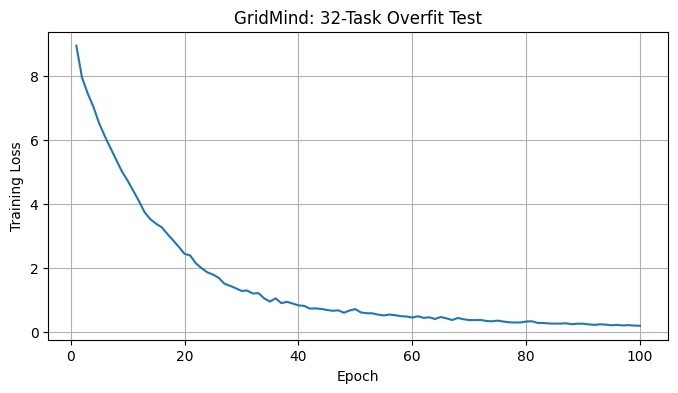

In [41]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(overfit_history) + 1),
    overfit_history
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("GridMind: 32-Task Overfit Test")
plt.grid(True)
plt.show()

In [66]:
@torch.no_grad()
def analyze_task_errors(model, loader):

    model.eval()

    results = []

    for batch in loader:

        sx = batch["support_inputs"].to(device)
        sy = batch["support_outputs"].to(device)
        qx = batch["query_input"].to(device)
        sm = batch["support_mask"].to(device)

        target = batch["query_target"].to(device)
        target_size = batch["target_size"].to(device)

        predictions = model(sx, sy, qx, sm)

        predicted_grid = predictions[
            "colour_logits"
        ].argmax(dim=1)

        predicted_h = (
            predictions["height_logits"].argmax(dim=1) + 1
        )

        predicted_w = (
            predictions["width_logits"].argmax(dim=1) + 1
        )

        for i in range(len(batch["task_id"])):

            true_h, true_w = target_size[i].tolist()

            pred_h = predicted_h[i].item()
            pred_w = predicted_w[i].item()

            actual = target[i, :true_h, :true_w]
            predicted = predicted_grid[i, :true_h, :true_w]

            wrong_cells = (actual != predicted).sum().item()
            total_cells = true_h * true_w

            size_correct = (
                pred_h == true_h and pred_w == true_w
            )

            grid_exact = size_correct and torch.equal(actual, predicted)
            
            results.append({
                "task_id": batch["task_id"][i],
                "actual_size": f"{true_h}x{true_w}",
                "predicted_size": f"{pred_h}x{pred_w}",
                "size_correct": size_correct,
                "wrong_cells": wrong_cells,
                "total_cells": total_cells,
                "cell_accuracy": 1 - wrong_cells / total_cells,
                "grid_exact": grid_exact
            })

    return results


error_results = analyze_task_errors(
    overfit_model,
    overfit_loader
)

error_results.sort(
    key=lambda x: x["wrong_cells"],
    reverse=True
)

for result in error_results[:10]:
    print(result)

{'task_id': '1e32b0e9', 'actual_size': '17x17', 'predicted_size': '17x17', 'size_correct': True, 'wrong_cells': 104, 'total_cells': 289, 'cell_accuracy': 0.6401384083044983, 'grid_exact': False}
{'task_id': '4e45f183', 'actual_size': '19x19', 'predicted_size': '19x19', 'size_correct': True, 'wrong_cells': 74, 'total_cells': 361, 'cell_accuracy': 0.7950138504155124, 'grid_exact': False}
{'task_id': '817e6c09', 'actual_size': '7x17', 'predicted_size': '7x17', 'size_correct': True, 'wrong_cells': 50, 'total_cells': 119, 'cell_accuracy': 0.5798319327731092, 'grid_exact': False}
{'task_id': '7df24a62', 'actual_size': '23x23', 'predicted_size': '23x23', 'size_correct': True, 'wrong_cells': 46, 'total_cells': 529, 'cell_accuracy': 0.9130434782608696, 'grid_exact': False}
{'task_id': '88207623', 'actual_size': '16x16', 'predicted_size': '16x16', 'size_correct': True, 'wrong_cells': 32, 'total_cells': 256, 'cell_accuracy': 0.875, 'grid_exact': False}
{'task_id': '759f3fd3', 'actual_size': '10x1

In [44]:
size_correct_tasks = [
    x for x in error_results if x["size_correct"]
]

grid_exact_tasks = [
    x for x in error_results if x["grid_exact"]
]

print("Total tasks:", len(error_results))

print("Correct size:", len(size_correct_tasks))

print("Exact grid matches:", len(grid_exact_tasks))

print(
    "Exact match among correct-size tasks:",
    sum(x["grid_exact"] for x in size_correct_tasks),
    "/",
    len(size_correct_tasks)
)

print(
    "Average wrong cells:",
    sum(x["wrong_cells"] for x in error_results)
    / len(error_results)
)

Total tasks: 32
Correct size: 29
Exact grid matches: 0
Exact match among correct-size tasks: 0 / 29
Average wrong cells: 21.0625


In [45]:
import matplotlib.pyplot as plt
import numpy as np
import json
import random

from matplotlib.colors import ListedColormap

ARC_COLORS = [
    "#000000", "#0074D9", "#FF4136", "#2ECC40",
    "#FFDC00", "#AAAAAA", "#F012BE", "#FF851B",
    "#7FDBFF", "#870C25"
]

cmap = ListedColormap(ARC_COLORS)


def visualize_task(task_id):

    idx = overfit_ids.index(task_id)

    # Reproduce the exact same query selection
    rng = random.Random(42 + idx)

    file_path = os.path.join(
        TRAIN_DIR, task_id + ".json"
    )

    with open(file_path) as f:
        task = json.load(f)

    examples = task["train"]

    query_idx = rng.randrange(len(examples))
    query = examples[query_idx]

    support = [
        ex for i, ex in enumerate(examples)
        if i != query_idx
    ]

    # Prepare model input
    sample = overfit_dataset[idx]
    batch = gridmind_collate([sample])

    sx = batch["support_inputs"].to(device)
    sy = batch["support_outputs"].to(device)
    qx = batch["query_input"].to(device)
    sm = batch["support_mask"].to(device)

    overfit_model.eval()

    with torch.no_grad():
        pred = overfit_model(sx, sy, qx, sm)

    predicted_grid = (
        pred["colour_logits"].argmax(dim=1)[0]
        .cpu().numpy()
    )

    ph = pred["height_logits"].argmax(dim=1).item() + 1
    pw = pred["width_logits"].argmax(dim=1).item() + 1

    predicted_grid = predicted_grid[:ph, :pw]

    n = len(support)

    fig, axes = plt.subplots(
        n + 1, 3,
        figsize=(12, 4 * (n + 1)),
        squeeze=False
    )

    for i, ex in enumerate(support):

        axes[i, 0].imshow(ex["input"], cmap=cmap, vmin=0, vmax=9)
        axes[i, 0].set_title(f"Support {i+1} Input")

        axes[i, 1].imshow(ex["output"], cmap=cmap, vmin=0, vmax=9)
        axes[i, 1].set_title(f"Support {i+1} Output")

        axes[i, 2].axis("off")

    row = n

    axes[row, 0].imshow(
        query["input"], cmap=cmap, vmin=0, vmax=9
    )
    axes[row, 0].set_title("Query Input")

    axes[row, 1].imshow(
        predicted_grid, cmap=cmap, vmin=0, vmax=9
    )
    axes[row, 1].set_title(f"Predicted ({ph}x{pw})")

    axes[row, 2].imshow(
        query["output"], cmap=cmap, vmin=0, vmax=9
    )
    axes[row, 2].set_title(
        f"Actual ({len(query['output'])}x{len(query['output'][0])})"
    )

    for ax in axes.flat:
        ax.axis("off")

    plt.suptitle(f"GridMind Task: {task_id}", fontsize=16)
    plt.tight_layout()
    plt.show()

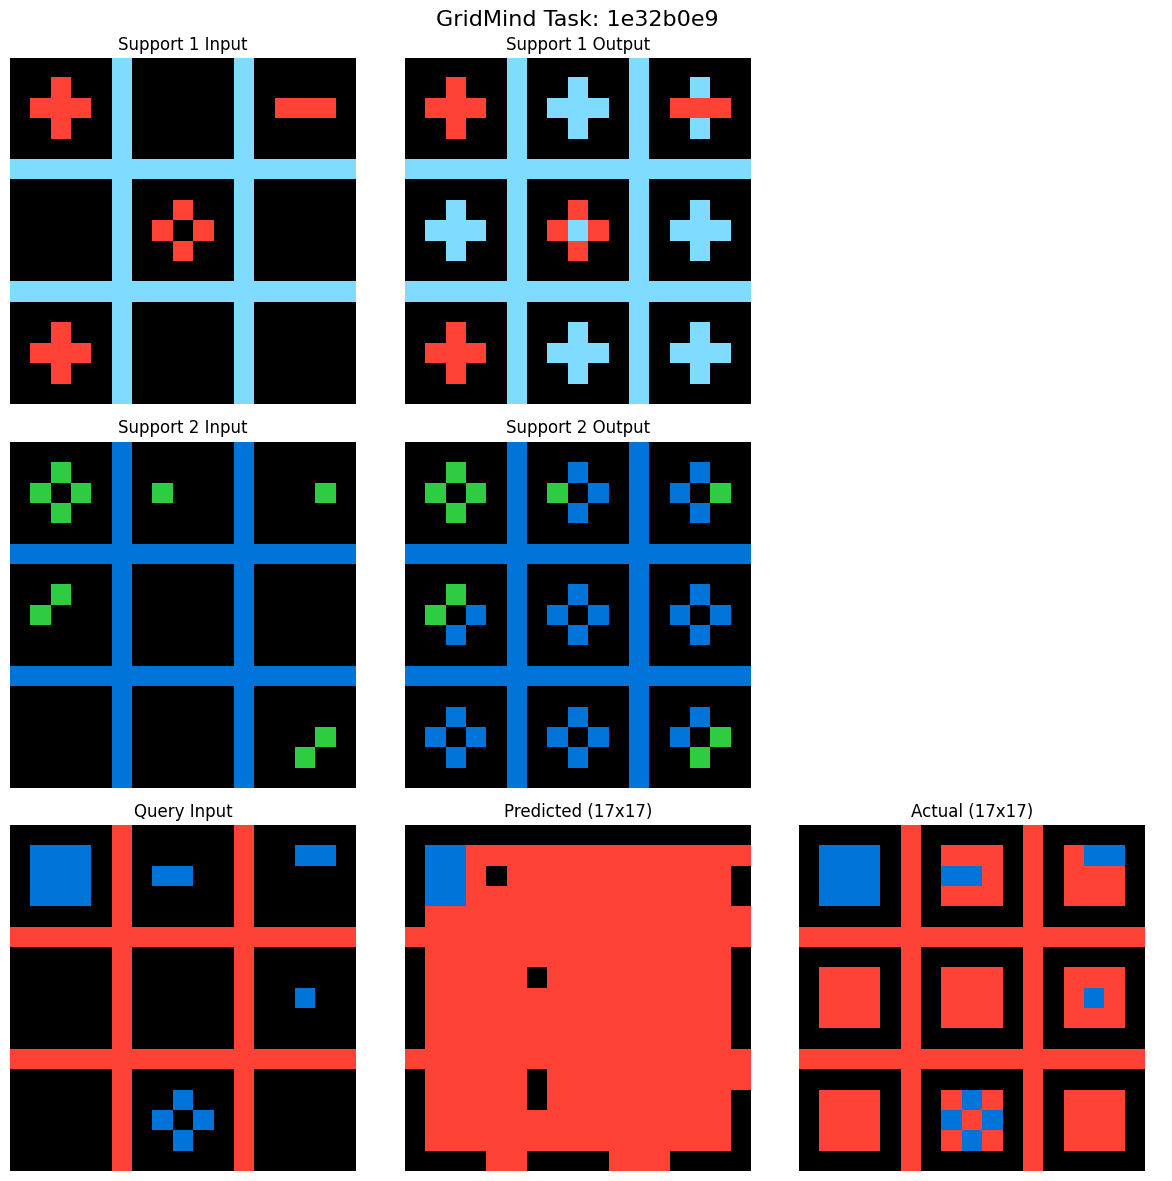

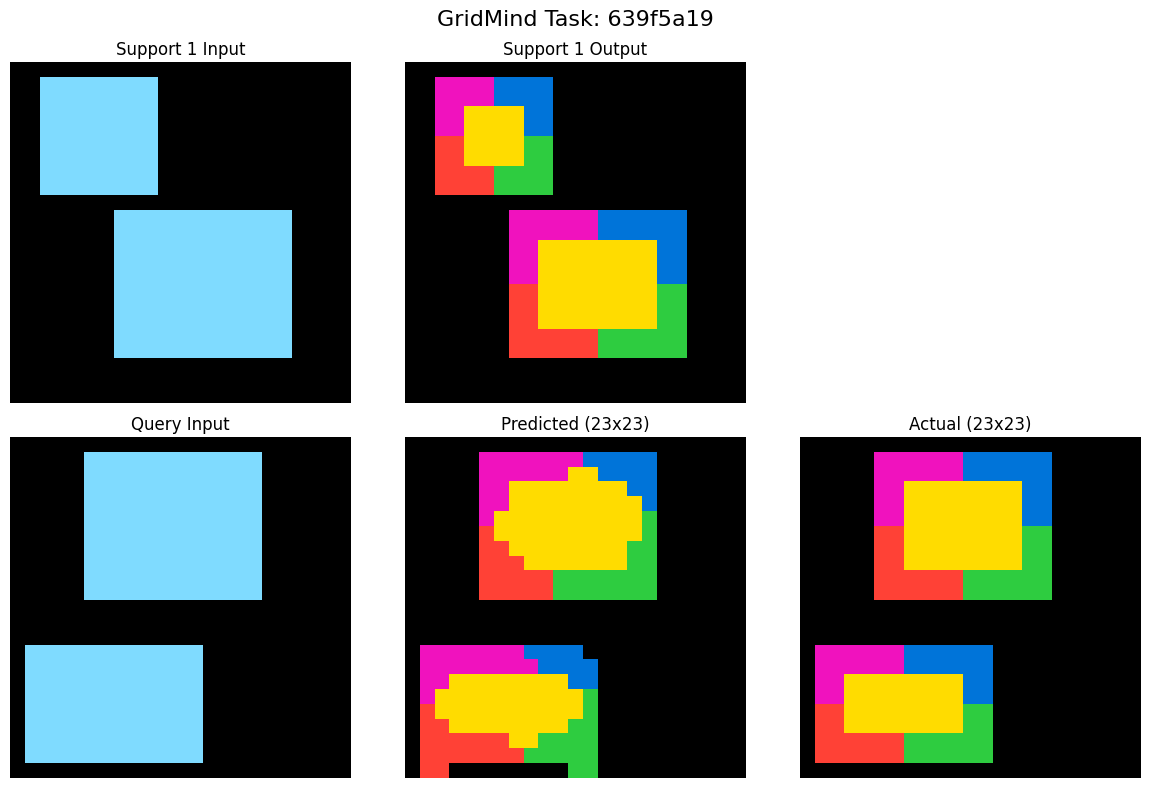

In [46]:
visualize_task("1e32b0e9")
visualize_task("639f5a19")

In [60]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

print("Checkpoint keys:", checkpoint.keys())

Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss', 'config'])


In [62]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", checkpoint.keys())
else:
    print("Checkpoint is a state dict")

Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss', 'config'])


In [63]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

model.to(device)
model.eval()

print("GridMind V3 checkpoint loaded successfully!")
print("Best Epoch:", checkpoint["epoch"])
print("Best Validation Loss:", checkpoint["best_val_loss"])

GridMind V3 checkpoint loaded successfully!
Best Epoch: 21
Best Validation Loss: 4.539649589061737


In [67]:
v3_errors = analyze_task_errors(model, val_loader)

exact_tasks = [
    x for x in v3_errors
    if x["grid_exact"]
]

print("Total Validation Tasks:", len(v3_errors))
print("Correct Size Tasks:", sum(x["size_correct"] for x in v3_errors))
print("Exact Match Tasks:", len(exact_tasks))

Total Validation Tasks: 200
Correct Size Tasks: 89
Exact Match Tasks: 1


In [68]:
# GridMind V3 - Error Distribution Analysis

total = len(v3_errors)

correct_size = [
    x for x in v3_errors
    if x["size_correct"]
]

wrong_size = [
    x for x in v3_errors
    if not x["size_correct"]
]

exact_match = [
    x for x in v3_errors
    if x["grid_exact"] and x["size_correct"]
]

correct_size_wrong_cells = [
    x for x in correct_size
    if x["wrong_cells"] > 0
]

wrong_size_zero_cell_errors = [
    x for x in wrong_size
    if x["wrong_cells"] == 0
]

print("=" * 45)
print("GRIDMIND V3 - ERROR DISTRIBUTION")
print("=" * 45)

print(f"Total Tasks: {total}")

print("\n1. SIZE ANALYSIS")
print(f"Correct Size: {len(correct_size)}")
print(f"Wrong Size: {len(wrong_size)}")

print("\n2. COLOUR ANALYSIS")
print(f"Correct Size but Wrong Cells: {len(correct_size_wrong_cells)}")
print(f"Wrong Size but Zero Cell Errors: {len(wrong_size_zero_cell_errors)}")

print("\n3. FINAL PERFORMANCE")
print(f"Exact Match: {len(exact_match)}")
print(f"Exact Match Percentage: {len(exact_match)/total*100:.2f}%")

print("\n4. TOP 10 BIGGEST CELL ERRORS")

for item in sorted(
    v3_errors,
    key=lambda x: x["wrong_cells"],
    reverse=True
)[:10]:
    print(
        item["task_id"],
        "| Actual:", item["actual_size"],
        "| Predicted:", item["predicted_size"],
        "| Wrong Cells:", item["wrong_cells"]
    )

GRIDMIND V3 - ERROR DISTRIBUTION
Total Tasks: 200

1. SIZE ANALYSIS
Correct Size: 89
Wrong Size: 111

2. COLOUR ANALYSIS
Correct Size but Wrong Cells: 88
Wrong Size but Zero Cell Errors: 1

3. FINAL PERFORMANCE
Exact Match: 1
Exact Match Percentage: 0.50%

4. TOP 10 BIGGEST CELL ERRORS
753ea09b | Actual: 30x30 | Predicted: 30x30 | Wrong Cells: 287
332202d5 | Actual: 16x16 | Predicted: 16x16 | Wrong Cells: 256
484b58aa | Actual: 29x29 | Predicted: 22x25 | Wrong Cells: 175
981add89 | Actual: 30x30 | Predicted: 20x30 | Wrong Cells: 153
8dae5dfc | Actual: 18x19 | Predicted: 22x21 | Wrong Cells: 151
a04b2602 | Actual: 20x20 | Predicted: 20x20 | Wrong Cells: 112
e6721834 | Actual: 11x10 | Predicted: 17x14 | Wrong Cells: 110
46f33fce | Actual: 20x20 | Predicted: 10x10 | Wrong Cells: 109
b1986d4b | Actual: 5x30 | Predicted: 20x22 | Wrong Cells: 101
39e1d7f9 | Actual: 27x27 | Predicted: 22x21 | Wrong Cells: 99


In [69]:
# GridMind V3 - Height & Width Analysis

height_correct = 0
width_correct = 0

height_errors = []
width_errors = []

for item in v3_errors:

    actual_h, actual_w = map(
        int, item["actual_size"].split("x")
    )

    pred_h, pred_w = map(
        int, item["predicted_size"].split("x")
    )

    if actual_h == pred_h:
        height_correct += 1

    if actual_w == pred_w:
        width_correct += 1

    height_errors.append(abs(actual_h - pred_h))
    width_errors.append(abs(actual_w - pred_w))


print("HEIGHT & WIDTH ANALYSIS")
print("=" * 40)

print(f"Height Correct: {height_correct}/200")
print(f"Height Accuracy: {height_correct/200*100:.2f}%")

print(f"\nWidth Correct: {width_correct}/200")
print(f"Width Accuracy: {width_correct/200*100:.2f}%")

print(f"\nAverage Height Error: {sum(height_errors)/200:.2f}")
print(f"Average Width Error: {sum(width_errors)/200:.2f}")

HEIGHT & WIDTH ANALYSIS
Height Correct: 112/200
Height Accuracy: 56.00%

Width Correct: 106/200
Width Accuracy: 53.00%

Average Height Error: 1.89
Average Width Error: 1.83


In [71]:
# Inspect Validation Batch Structure

batch = next(iter(val_loader))

print("Available Batch Keys:")
for key, value in batch.items():
    if torch.is_tensor(value):
        print(
            f"{key}: Shape = {value.shape}, "
            f"Type = {value.dtype}"
        )
    else:
        print(f"{key}: Type = {type(value)}")

Available Batch Keys:
support_inputs: Shape = torch.Size([2, 4, 11, 30, 30]), Type = torch.float32
support_outputs: Shape = torch.Size([2, 4, 11, 30, 30]), Type = torch.float32
support_mask: Shape = torch.Size([2, 4]), Type = torch.bool
query_input: Shape = torch.Size([2, 11, 30, 30]), Type = torch.float32
query_target: Shape = torch.Size([2, 30, 30]), Type = torch.int64
query_size: Shape = torch.Size([2, 2]), Type = torch.int64
target_size: Shape = torch.Size([2, 2]), Type = torch.int64
task_id: Type = <class 'list'>


In [72]:
# Extract Support Input and Output Sizes

batch = next(iter(val_loader))

support_inputs = batch["support_inputs"]
support_outputs = batch["support_outputs"]
support_mask = batch["support_mask"]

def extract_grid_sizes(grids):
    # Last channel = valid cell mask
    valid_mask = grids[:, :, 10, :, :] > 0.5

    heights = valid_mask.any(dim=3).sum(dim=2)
    widths = valid_mask.any(dim=2).sum(dim=2)

    return heights, widths


input_h, input_w = extract_grid_sizes(support_inputs)
output_h, output_w = extract_grid_sizes(support_outputs)

print("Support Input Sizes:")
print("Height:", input_h)
print("Width:", input_w)

print("\nSupport Output Sizes:")
print("Height:", output_h)
print("Width:", output_w)

print("\nQuery Input Sizes:")
print(batch["query_size"])

print("\nQuery Target Sizes:")
print(batch["target_size"])

Support Input Sizes:
Height: tensor([[ 3,  3,  3,  3],
        [15, 18,  0,  0]])
Width: tensor([[ 3,  3,  3,  3],
        [15, 18,  0,  0]])

Support Output Sizes:
Height: tensor([[ 9,  9,  9,  9],
        [15, 18,  0,  0]])
Width: tensor([[ 9,  9,  9,  9],
        [15, 18,  0,  0]])

Query Input Sizes:
tensor([[ 3,  3],
        [18, 18]])

Query Target Sizes:
tensor([[ 9,  9],
        [18, 18]])


In [73]:
# Support-to-Query Size Pattern Analysis

@torch.no_grad()
def analyze_support_size_patterns(loader):

    results = []

    for batch in loader:

        sx = batch["support_inputs"]
        sy = batch["support_outputs"]
        sm = batch["support_mask"]

        q_size = batch["query_size"]
        target_size = batch["target_size"]

        in_h, in_w = extract_grid_sizes(sx)
        out_h, out_w = extract_grid_sizes(sy)

        for i in range(len(batch["task_id"])):

            valid = sm[i]

            ih = in_h[i][valid]
            iw = in_w[i][valid]
            oh = out_h[i][valid]
            ow = out_w[i][valid]

            if len(ih) == 0:
                continue

            # Check whether all support pairs share same
            # height and width transformation
            h_ratios = oh.float() / ih.float()
            w_ratios = ow.float() / iw.float()

            h_consistent = torch.allclose(
                h_ratios, h_ratios[:1].expand_as(h_ratios)
            )

            w_consistent = torch.allclose(
                w_ratios, w_ratios[:1].expand_as(w_ratios)
            )

            predicted_h = round(
                q_size[i][0].item() * h_ratios[0].item()
            )

            predicted_w = round(
                q_size[i][1].item() * w_ratios[0].item()
            )

            actual_h, actual_w = target_size[i].tolist()

            results.append({
                "task_id": batch["task_id"][i],
                "h_consistent": h_consistent,
                "w_consistent": w_consistent,
                "predicted_size": f"{predicted_h}x{predicted_w}",
                "actual_size": f"{actual_h}x{actual_w}",
                "size_correct": (
                    predicted_h == actual_h
                    and predicted_w == actual_w
                )
            })

    return results


size_pattern_results = analyze_support_size_patterns(val_loader)

consistent = [
    x for x in size_pattern_results
    if x["h_consistent"] and x["w_consistent"]
]

correct = [
    x for x in consistent
    if x["size_correct"]
]

print("Total Tasks:", len(size_pattern_results))
print("Consistent Support Patterns:", len(consistent))
print("Correct Size Predictions from Support Pattern:", len(correct))

if consistent:
    print(
        "Pattern-based Size Accuracy:",
        f"{len(correct)/len(consistent)*100:.2f}%"
    )

print("\nSample Results:")
for x in consistent[:10]:
    print(x)

Total Tasks: 200
Consistent Support Patterns: 166
Correct Size Predictions from Support Pattern: 161
Pattern-based Size Accuracy: 96.99%

Sample Results:
{'task_id': '8b28cd80', 'h_consistent': True, 'w_consistent': True, 'predicted_size': '9x9', 'actual_size': '9x9', 'size_correct': True}
{'task_id': 'bd14c3bf', 'h_consistent': True, 'w_consistent': True, 'predicted_size': '18x18', 'actual_size': '18x18', 'size_correct': True}
{'task_id': 'bd5af378', 'h_consistent': True, 'w_consistent': True, 'predicted_size': '10x10', 'actual_size': '10x10', 'size_correct': True}
{'task_id': 'aaef0977', 'h_consistent': True, 'w_consistent': True, 'predicted_size': '8x8', 'actual_size': '8x8', 'size_correct': True}
{'task_id': '6d0aefbc', 'h_consistent': True, 'w_consistent': True, 'predicted_size': '3x6', 'actual_size': '3x6', 'size_correct': True}
{'task_id': 'a406ac07', 'h_consistent': True, 'w_consistent': True, 'predicted_size': '10x10', 'actual_size': '10x10', 'size_correct': True}
{'task_id': 

In [74]:
# GridMind V3 - Hybrid Size Prediction Evaluation

v3_lookup = {
    x["task_id"]: x for x in v3_errors
}

pattern_lookup = {
    x["task_id"]: x for x in size_pattern_results
}

hybrid_correct = 0
support_rule_used = 0
v3_fallback_used = 0
fallback_correct = 0

hybrid_results = []

for task_id, v3_item in v3_lookup.items():

    pattern = pattern_lookup.get(task_id)

    if pattern is None:
        continue

    actual_size = v3_item["actual_size"]

    if pattern["h_consistent"] and pattern["w_consistent"]:

        predicted_size = pattern["predicted_size"]
        support_rule_used += 1

    else:

        predicted_size = v3_item["predicted_size"]
        v3_fallback_used += 1

        if v3_item["size_correct"]:
            fallback_correct += 1

    correct = predicted_size == actual_size

    if correct:
        hybrid_correct += 1

    hybrid_results.append({
        "task_id": task_id,
        "actual_size": actual_size,
        "predicted_size": predicted_size,
        "correct": correct
    })


total = len(hybrid_results)

print("=" * 45)
print("GRIDMIND V3 - HYBRID SIZE EVALUATION")
print("=" * 45)

print("Total Tasks:", total)

print("\nSupport Rule Used:", support_rule_used)
print("V3 Fallback Used:", v3_fallback_used)
print("V3 Fallback Correct:", fallback_correct)

print("\nHybrid Correct:", hybrid_correct)
print(
    "Hybrid Size Accuracy:",
    f"{hybrid_correct / total * 100:.2f}%"
)

print("\nV3 Original Size Accuracy: 44.50%")

GRIDMIND V3 - HYBRID SIZE EVALUATION
Total Tasks: 200

Support Rule Used: 166
V3 Fallback Used: 34
V3 Fallback Correct: 4

Hybrid Correct: 165
Hybrid Size Accuracy: 82.50%

V3 Original Size Accuracy: 44.50%


In [75]:
# GridMind V3 - Same Episode Hybrid Evaluation

@torch.no_grad()
def evaluate_hybrid_same_episode(loader):

    model.eval()

    total = 0
    hybrid_correct = 0
    neural_correct = 0
    support_used = 0
    fallback_used = 0

    for batch in loader:

        sx = batch["support_inputs"].to(device)
        sy = batch["support_outputs"].to(device)
        qx = batch["query_input"].to(device)
        sm = batch["support_mask"].to(device)

        target_size = batch["target_size"]

        predictions = model(sx, sy, qx, sm)

        neural_h = (
            predictions["height_logits"].argmax(dim=1) + 1
        ).cpu()

        neural_w = (
            predictions["width_logits"].argmax(dim=1) + 1
        ).cpu()

        in_h, in_w = extract_grid_sizes(
            batch["support_inputs"]
        )

        out_h, out_w = extract_grid_sizes(
            batch["support_outputs"]
        )

        for i in range(len(batch["task_id"])):

            valid = batch["support_mask"][i]

            ih = in_h[i][valid]
            iw = in_w[i][valid]
            oh = out_h[i][valid]
            ow = out_w[i][valid]

            actual_h, actual_w = target_size[i].tolist()

            h_ok = len(ih) > 0 and torch.allclose(
                oh.float() / ih.float(),
                (oh.float() / ih.float())[0].expand_as(oh.float())
            )

            w_ok = len(iw) > 0 and torch.allclose(
                ow.float() / iw.float(),
                (ow.float() / iw.float())[0].expand_as(ow.float())
            )

            if h_ok and w_ok:

                qh, qw = batch["query_size"][i].tolist()

                pred_h = round(
                    qh * (oh[0].item() / ih[0].item())
                )

                pred_w = round(
                    qw * (ow[0].item() / iw[0].item())
                )

                support_used += 1

            else:

                pred_h = neural_h[i].item()
                pred_w = neural_w[i].item()

                fallback_used += 1

            if neural_h[i].item() == actual_h and neural_w[i].item() == actual_w:
                neural_correct += 1

            if pred_h == actual_h and pred_w == actual_w:
                hybrid_correct += 1

            total += 1

    print("Same-Episode Hybrid Evaluation")
    print("=" * 40)
    print("Total Tasks:", total)
    print("Support Rule Used:", support_used)
    print("Neural Fallback Used:", fallback_used)
    print("Neural Size Accuracy:", f"{neural_correct/total*100:.2f}%")
    print("Hybrid Size Accuracy:", f"{hybrid_correct/total*100:.2f}%")


evaluate_hybrid_same_episode(val_loader)

Same-Episode Hybrid Evaluation
Total Tasks: 200
Support Rule Used: 166
Neural Fallback Used: 34
Neural Size Accuracy: 44.50%
Hybrid Size Accuracy: 82.50%


In [76]:
# GridMind V3 - Hybrid End-to-End Evaluation

@torch.no_grad()
def evaluate_hybrid_full(loader):

    model.eval()

    total = 0
    size_correct = 0
    exact_match = 0
    colour_exact_on_correct_size = 0

    total_cells = 0
    correct_cells = 0

    for batch in loader:

        sx = batch["support_inputs"].to(device)
        sy = batch["support_outputs"].to(device)
        qx = batch["query_input"].to(device)
        sm = batch["support_mask"].to(device)

        target = batch["query_target"]
        target_size = batch["target_size"]

        predictions = model(sx, sy, qx, sm)

        colour_pred = predictions["colour_logits"].argmax(dim=1).cpu()

        neural_h = predictions["height_logits"].argmax(dim=1).cpu() + 1
        neural_w = predictions["width_logits"].argmax(dim=1).cpu() + 1

        in_h, in_w = extract_grid_sizes(batch["support_inputs"])
        out_h, out_w = extract_grid_sizes(batch["support_outputs"])

        for i in range(len(batch["task_id"])):

            valid = batch["support_mask"][i]

            ih = in_h[i][valid]
            iw = in_w[i][valid]
            oh = out_h[i][valid]
            ow = out_w[i][valid]

            actual_h, actual_w = target_size[i].tolist()

            h_ratio = oh.float() / ih.float()
            w_ratio = ow.float() / iw.float()

            h_ok = len(ih) > 0 and torch.allclose(
                h_ratio, h_ratio[0].expand_as(h_ratio)
            )

            w_ok = len(iw) > 0 and torch.allclose(
                w_ratio, w_ratio[0].expand_as(w_ratio)
            )

            if h_ok and w_ok:

                qh, qw = batch["query_size"][i].tolist()

                pred_h = round(qh * h_ratio[0].item())
                pred_w = round(qw * w_ratio[0].item())

            else:
                pred_h = neural_h[i].item()
                pred_w = neural_w[i].item()

            actual_grid = target[i, :actual_h, :actual_w]
            predicted_grid = colour_pred[i, :actual_h, :actual_w]

            cell_matches = (actual_grid == predicted_grid).sum().item()

            correct_cells += cell_matches
            total_cells += actual_h * actual_w

            is_size_correct = (
                pred_h == actual_h and pred_w == actual_w
            )

            if is_size_correct:
                size_correct += 1

                is_colour_exact = torch.equal(
                    actual_grid, predicted_grid
                )

                if is_colour_exact:
                    colour_exact_on_correct_size += 1
                    exact_match += 1

            total += 1

    print("=" * 45)
    print("GRIDMIND V3 - HYBRID FULL EVALUATION")
    print("=" * 45)

    print("Total Tasks:", total)
    print(
        "Hybrid Size Accuracy:",
        f"{size_correct / total * 100:.2f}%"
    )
    print(
        "Cell Accuracy:",
        f"{correct_cells / total_cells * 100:.2f}%"
    )
    print(
        "Exact Match:",
        f"{exact_match}/{total} ({exact_match / total * 100:.2f}%)"
    )
    print(
        "Colour Exact on Correct-Size Tasks:",
        f"{colour_exact_on_correct_size}/{size_correct}"
    )


evaluate_hybrid_full(val_loader)

GRIDMIND V3 - HYBRID FULL EVALUATION
Total Tasks: 200
Hybrid Size Accuracy: 82.50%
Cell Accuracy: 78.73%
Exact Match: 1/200 (0.50%)
Colour Exact on Correct-Size Tasks: 1/165
